In [24]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix

In [25]:
data = pd.read_csv('ecg.csv', header=None)
x= data.iloc[:,:-1].values
y=data.iloc[:,-1].values

In [26]:
#TTS
x_train, x_test, y_train, y_test= tts(x,y, test_size=0.2, stratify=y, random_state=42)
x_train= x_train[y_train==1]

In [27]:
#Normalize
scaler = MinMaxScaler()
x_train_s= scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)
print("train shape after scaling: ", x_train_s.shape)
print("test shape after scaling: ", x_test_s.shape)

train shape after scaling:  (2335, 140)
test shape after scaling:  (1000, 140)


In [28]:
input_dim = x_train_s.shape[1]
autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(input_dim, activation='sigmoid')
])

In [30]:
autoencoder.compile(optimizer=keras.optimizers.Adam(0.001), loss='mean_squared_logarithmic_error', metrics=['mse'])
autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                     │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
history = autoencoder.fit(x_train_s, x_train_s, epochs=20 ,batch_size=512, validation_data=(x_test_s, x_test_s), verbose=1)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0109 - mse: 0.0247 - val_loss: 0.0132 - val_mse: 0.0307
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0107 - mse: 0.0242 - val_loss: 0.0130 - val_mse: 0.0303
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0104 - mse: 0.0235 - val_loss: 0.0126 - val_mse: 0.0294
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0097 - mse: 0.0219 - val_loss: 0.0121 - val_mse: 0.0281
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0085 - mse: 0.0192 - val_loss: 0.0118 - val_mse: 0.0275
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0074 - mse: 0.0165 - val_loss: 0.0118 - val_mse: 0.0272
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0063 - mse: 0.0141 - val_loss: 0.0113 - val_mse: 0.0262
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0055 - mse: 0.0123 - val_loss: 0.0114 - val_mse: 0.0263
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0050 - mse: 0.0111 - 

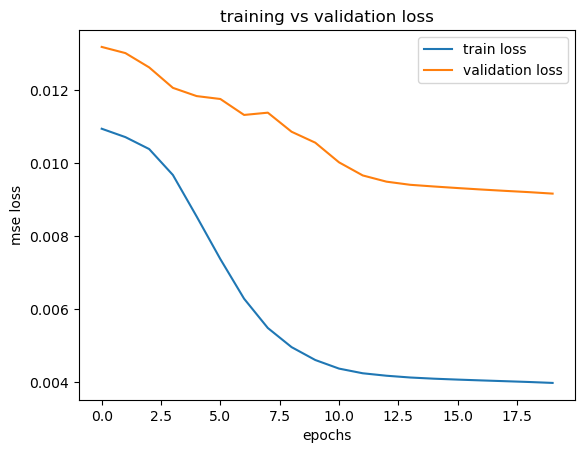

In [32]:
# plot loss
plt.plot(history.history['loss'], label = "train loss")
plt.plot(history.history['val_loss'], label = "validation loss")
plt.xlabel("epochs")
plt.ylabel("mse loss")
plt.title("training vs validation loss")
plt.legend()
plt.show()

In [36]:
#Reconstruction error
recon_train = autoencoder.predict(x_train_s)
recon_test = autoencoder.predict(x_test_s)
train_err = np.mean(np.square(x_train_s - recon_train), axis=1)
test_err = np.mean(np.square(x_test_s - recon_test), axis=1)

#Threshold
threshold = np.mean(train_err) + np.std(train_err)

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


Reconstruction Threshold:  0.019797697895756784
Accuracy:  0.057
Confusion Matrix: 
 [[  5 411]
 [532  52]]


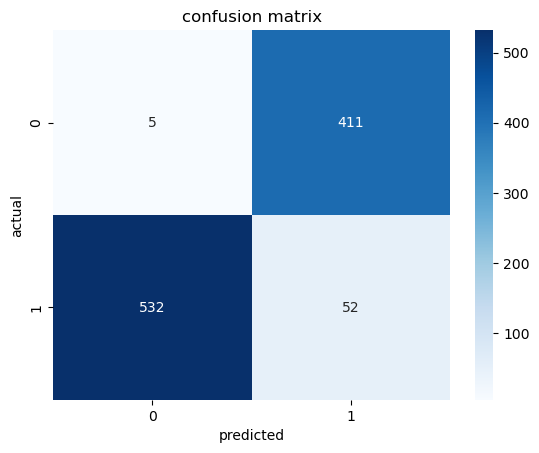

In [37]:
#Predictions
y_pred = [1 if e > threshold else 0 for e in test_err]
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Reconstruction Threshold: ", threshold)
print("Accuracy: ", acc)

print("Confusion Matrix: \n", cm)
sns.heatmap(cm, annot = True, fmt="d", cmap="Blues")
plt.title("confusion matrix")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()